<a href="https://colab.research.google.com/github/leopxz/Detec-o_fraude/blob/main/deteccao_fraude.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

df = pd.read_csv(url)

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


**Etapa 1 — Exploração**



Linhas e colunas: (284807, 31)
Nulos: 0
Class
0    99.827
1     0.173
Name: % por classe, dtype: float64


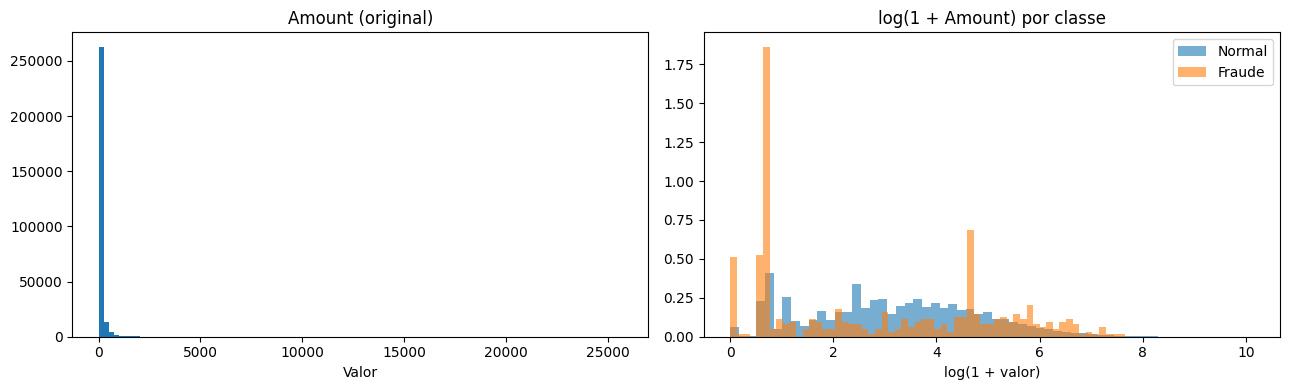

In [3]:
import numpy as np
import matplotlib.pyplot as plt

print("Linhas e colunas:", df.shape)
print("Nulos:", df.isnull().sum().sum())
print(df["Class"].value_counts(normalize=True).mul(100).round(3).rename("% por classe"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Valor original: a maioria das transações é pequena, mas há valores enormes
axes[0].hist(df["Amount"], bins=100)
axes[0].set_title("Amount (original)")
axes[0].set_xlabel("Valor")

# Valor em log: distribuição bem mais equilibrada
axes[1].hist(np.log1p(df.loc[df["Class"] == 0, "Amount"]), bins=60, alpha=0.6, density=True, label="Normal")
axes[1].hist(np.log1p(df.loc[df["Class"] == 1, "Amount"]), bins=60, alpha=0.6, density=True, label="Fraude")
axes[1].set_title("log(1 + Amount) por classe")
axes[1].set_xlabel("log(1 + valor)")
axes[1].legend()

plt.tight_layout()
plt.show()

**O que esperar:** o gráfico da esquerda fica espremido no começo, com quase tudo perto de zero e uma cauda longa. O da direita, em log, mostra as duas classes de forma legível. Esse contraste justifica a variável que criamos a seguir.

**Etapa 2 — Preparação**

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df_prep = df.copy()

# Novas variáveis
df_prep["log_amount"] = np.log1p(df_prep["Amount"])      # log(1 + valor); o +1 evita erro com valor 0
df_prep["hora"] = (df_prep["Time"] // 3600) % 24         # hora relativa do dia (0 a 23)

# X = variáveis de entrada, y = resposta (fraude ou não)
X = df_prep.drop(columns=["Class", "Amount", "Time"])
y = df_prep["Class"]

# Separação treino/teste mantendo a proporção de fraudes
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Padronização: aprende média e desvio SÓ no treino, depois aplica nos dois
scaler = StandardScaler()
X_train_sc = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_sc = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print("Treino:", X_train.shape, "| fraudes:", y_train.sum(), f"({y_train.mean()*100:.3f}%)")
print("Teste: ", X_test.shape, "| fraudes:", y_test.sum(), f"({y_test.mean()*100:.3f}%)")

Treino: (227845, 30) | fraudes: 394 (0.173%)
Teste:  (56962, 30) | fraudes: 98 (0.172%)


**O que cada parte faz:**

**log_amount:** comprime os valores muito altos, para que uma transação de R$ 20 mil não domine o modelo. Amount original sai de X para não ficar duplicado.

**hora:** Time conta segundos desde a primeira transação, ao longo de dois dias. Dividindo por 3600 e pegando o resto por 24, temos uma hora do dia relativa. A base não informa a que horas começou, então “hora 0” não é necessariamente meia-noite. Vale citar isso no README.

**stratify=y:** sem isso, o sorteio poderia colocar pouquíssimas fraudes no teste e a avaliação ficaria pouco confiável.

**random_state=42:** garante que a separação seja sempre a mesma, para que os resultados sejam reproduzíveis.

**fit_transform** no treino, **transform** no teste: o scaler aprende média e desvio só com os dados de treino. Se ele “visse” o teste, haveria vazamento de informação e as métricas ficariam otimistas demais.

**Etapa 3 — Treinar os modelos**

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Quantas normais existem para cada fraude no treino (~577)
peso = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Peso da classe fraude: {peso:.0f}")

modelos = {
    "Regressão Logística": LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, class_weight="balanced_subsample",
        min_samples_leaf=2, n_jobs=-1, random_state=42
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.1,
        scale_pos_weight=peso, eval_metric="aucpr",
        n_jobs=-1, random_state=42
    ),
}

probas = {}
for nome, modelo in modelos.items():
    modelo.fit(X_train_sc, y_train)
    probas[nome] = modelo.predict_proba(X_test_sc)[:, 1]   # probabilidade de ser fraude
    print(f"{nome}: treinado")

Peso da classe fraude: 577
Regressão Logística: treinado
Random Forest: treinado
XGBoost: treinado


**Regressão logística é o baseline:** simples, rápida e fácil de interpretar. Os outros modelos precisam superá-la para justificar a complexidade.
class_weight / scale_pos_weight fazem cada erro em fraude “custar” centenas de vezes mais que um erro em transação normal. Sem isso, o modelo aprende a ignorar a fraude.
predict_proba guarda a probabilidade em vez do “sim/não”. É com ela que ajustamos o limiar na etapa 4.

O Random Forest pode levar uns 2 minutos. Os outros são rápidos.

**Etapa 4 — Avaliar**


**4.1 Tabela comparativa com o limiar padrão (0,5)**

In [7]:
from sklearn.metrics import (recall_score, precision_score, f1_score,
                             roc_auc_score, average_precision_score,
                             classification_report)

def avaliar(y_true, proba, limiar=0.5):
    pred = (proba >= limiar).astype(int)
    return {
        "Recall": recall_score(y_true, pred),
        "Precisão": precision_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred),
        "ROC AUC": roc_auc_score(y_true, proba),
        "PR AUC": average_precision_score(y_true, proba),
    }

resultados = pd.DataFrame({nome: avaliar(y_test, p) for nome, p in probas.items()}).T.round(3)
resultados

,Recall,Precisão,F1,ROC AUC,PR AUC
Regressão Logística,0.908,0.055,0.104,0.971,0.713
Random Forest,0.776,0.938,0.849,0.963,0.875
XGBoost,0.857,0.824,0.840,0.985,0.871


In [8]:
for nome, p in probas.items():
    print(f"===== {nome} =====")
    print(classification_report(y_test, (p >= 0.5).astype(int),
                                target_names=["Normal", "Fraude"], digits=3))

===== Regressão Logística =====
              precision    recall  f1-score   support

      Normal      1.000     0.973     0.986     56864
      Fraude      0.055     0.908     0.104        98

    accuracy                          0.973     56962
   macro avg      0.528     0.941     0.545     56962
weighted avg      0.998     0.973     0.985     56962

===== Random Forest =====
              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000     56864
      Fraude      0.938     0.776     0.849        98

    accuracy                          1.000     56962
   macro avg      0.969     0.888     0.924     56962
weighted avg      1.000     1.000     1.000     56962

===== XGBoost =====
              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000     56864
      Fraude      0.824     0.857     0.840        98

    accuracy                          0.999     56962
   macro avg      0.912     0.928     0.920     56

**Como ler:** olhe só a linha Fraude do relatório. A acurácia vai aparecer perto de 99% em todos os modelos e não diz nada. Um padrão comum é a regressão logística ter recall alto, mas precisão muito baixa, marcando muito cliente honesto. As árvores costumam equilibrar melhor os dois. Os números exatos dependem da execução.

PR AUC (área sob a curva precisão-recall) é o melhor número único para comparar modelos aqui. Ele resume o desempenho em todos os limiares possíveis.

**4.2 Curvas ROC e precisão-recall**

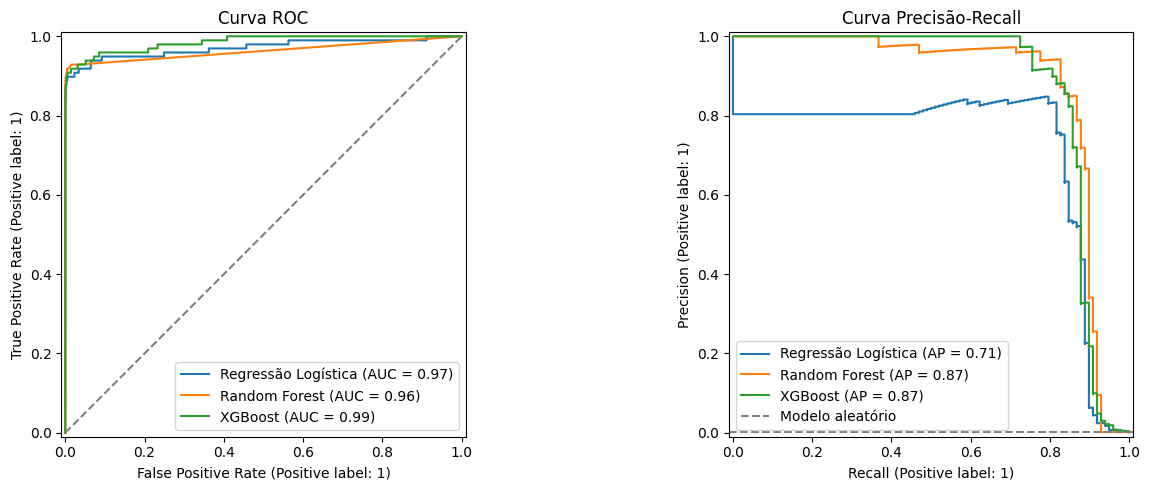

In [9]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for nome, p in probas.items():
    RocCurveDisplay.from_predictions(y_test, p, name=nome, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, p, name=nome, ax=axes[1])

axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("Curva ROC")
axes[1].axhline(y_test.mean(), ls="--", color="gray", label="Modelo aleatório")
axes[1].set_title("Curva Precisão-Recall")
axes[1].legend()
plt.tight_layout()
plt.show()

Repare que na ROC todos os modelos parecem quase perfeitos, colados no canto superior esquerdo. Na curva precisão-recall as diferenças aparecem. É exatamente o argumento do README: em dados desbalanceados, a ROC engana e a PR mostra a verdade.

**4.3 Ajuste do limiar de decisão**

Cuidado importante: o limiar não pode ser escolhido olhando o conjunto de teste. Isso seria “colar” na prova. Usamos validação cruzada só no treino para escolher, e depois aplicamos no teste.

Modelo escolhido para ajuste de limiar: Random Forest
Limiar escolhido: 0.100


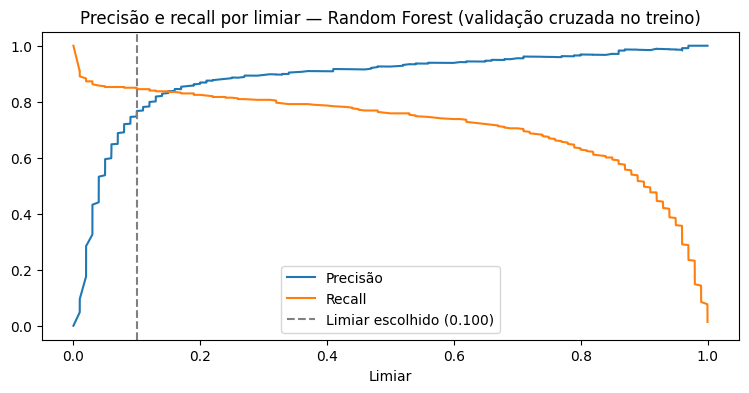

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve

melhor = resultados["PR AUC"].idxmax()
print("Modelo escolhido para ajuste de limiar:", melhor)

# Probabilidades "fora da dobra": cada linha do treino é prevista por um modelo que não a viu
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
proba_oof = cross_val_predict(clone(modelos[melhor]), X_train_sc, y_train,
                              cv=cv, method="predict_proba")[:, 1]

prec, rec, limiares = precision_recall_curve(y_train, proba_oof)
prec, rec = prec[:-1], rec[:-1]   # alinha com o vetor de limiares

# Critério: recall de pelo menos 85%, com a maior precisão possível
RECALL_MINIMO = 0.85
ok = rec >= RECALL_MINIMO
limiar = limiares[ok][np.argmax(prec[ok])]
print(f"Limiar escolhido: {limiar:.3f}")

# Gráfico: como precisão e recall mudam conforme o limiar
plt.figure(figsize=(9, 4))
plt.plot(limiares, prec, label="Precisão")
plt.plot(limiares, rec, label="Recall")
plt.axvline(limiar, ls="--", color="gray", label=f"Limiar escolhido ({limiar:.3f})")
plt.xlabel("Limiar")
plt.title(f"Precisão e recall por limiar — {melhor} (validação cruzada no treino)")
plt.legend()
plt.show()

,Recall,Precisão,F1,ROC AUC,PR AUC
"Limiar 0,5",0.776,0.938,0.849,0.963,0.875
Limiar 0.100,0.888,0.690,0.777,0.963,0.875


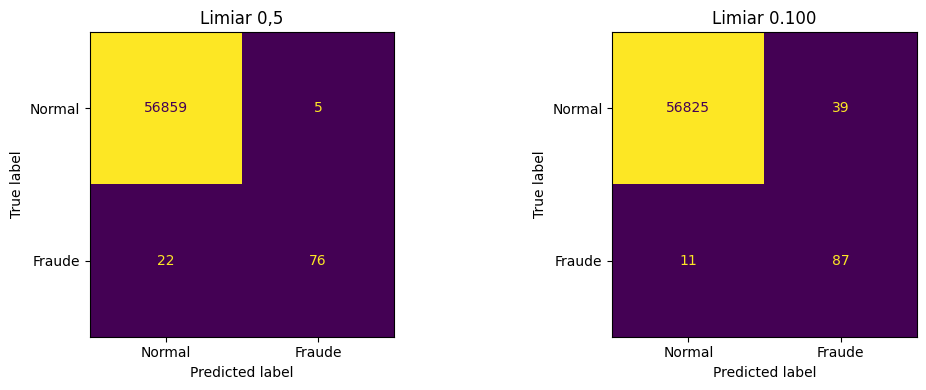

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay

comparacao = pd.DataFrame({
    "Limiar 0,5": avaliar(y_test, probas[melhor], 0.5),
    f"Limiar {limiar:.3f}": avaliar(y_test, probas[melhor], limiar),
}).T.round(3)
display(comparacao)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (titulo, lim) in zip(axes, [("Limiar 0,5", 0.5), (f"Limiar {limiar:.3f}", limiar)]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (probas[melhor] >= lim).astype(int),
        display_labels=["Normal", "Fraude"], ax=ax, colorbar=False
    )
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

A matriz de confusão traduz as métricas em casos concretos. Por exemplo, “das 98 fraudes do teste, pegamos X e deixamos passar Y; e bloqueamos Z clientes honestos”. Use esses números no README, porque são muito mais fáceis de entender do que porcentagens.

O critério de 85% é uma decisão de negócio, não uma verdade técnica. Você pode mudar RECALL_MINIMO para 0,80 ou 0,90 e mostrar o efeito. Só justifique a escolha.

**Etapa 5 — Explicar o modelo**

**5.1 Importância das variáveis**

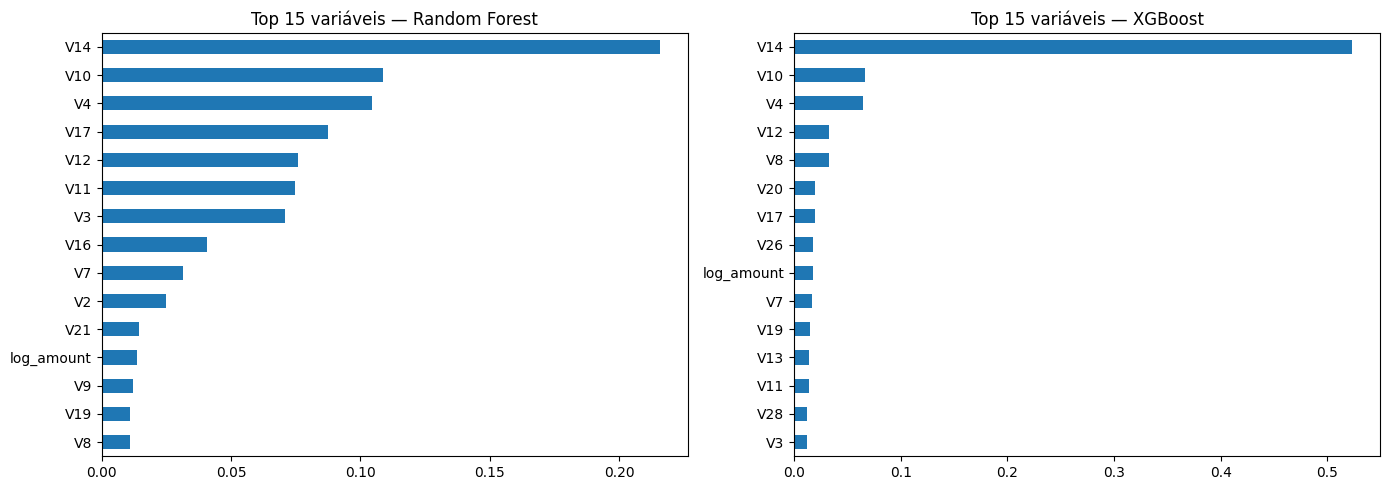

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, nome in zip(axes, ["Random Forest", "XGBoost"]):
    imp = pd.Series(modelos[nome].feature_importances_, index=X.columns).nlargest(15)
    imp.sort_values().plot(kind="barh", ax=ax)
    ax.set_title(f"Top 15 variáveis — {nome}")
plt.tight_layout()
plt.show()

Isso mostra quais variáveis o modelo usa mais em geral, mas não diz em que direção elas empurram a decisão. Para isso entra o SHAP.

**5.2 SHARP**

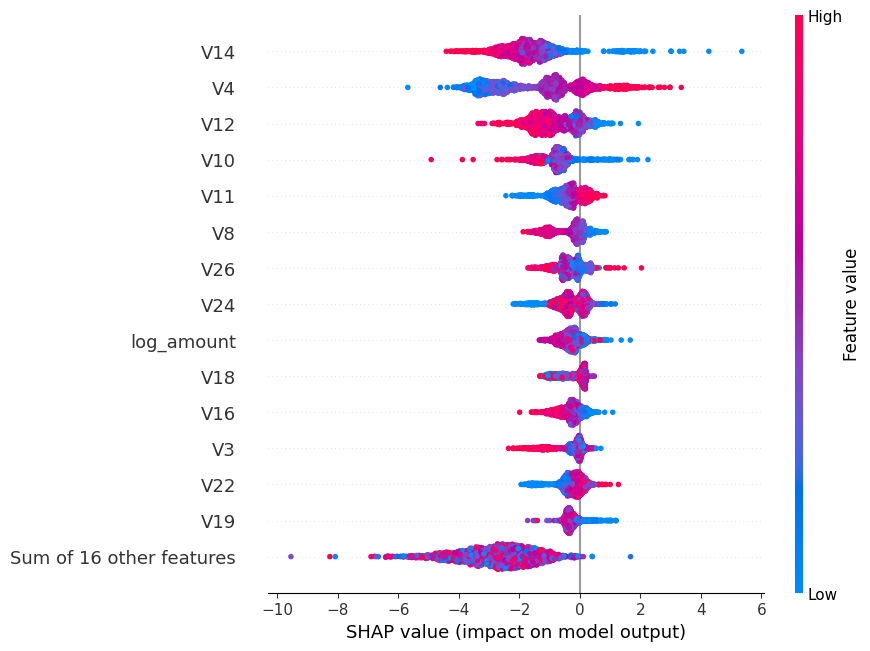

In [13]:
!pip install -q shap
import shap

explainer = shap.TreeExplainer(modelos["XGBoost"])

# Visão geral (amostra de 2.000 transações para ficar rápido)
amostra = X_test_sc.sample(2000, random_state=42)
shap_amostra = explainer(amostra)
shap.plots.beeswarm(shap_amostra, max_display=15)

Probabilidade de fraude atribuída: 1.000


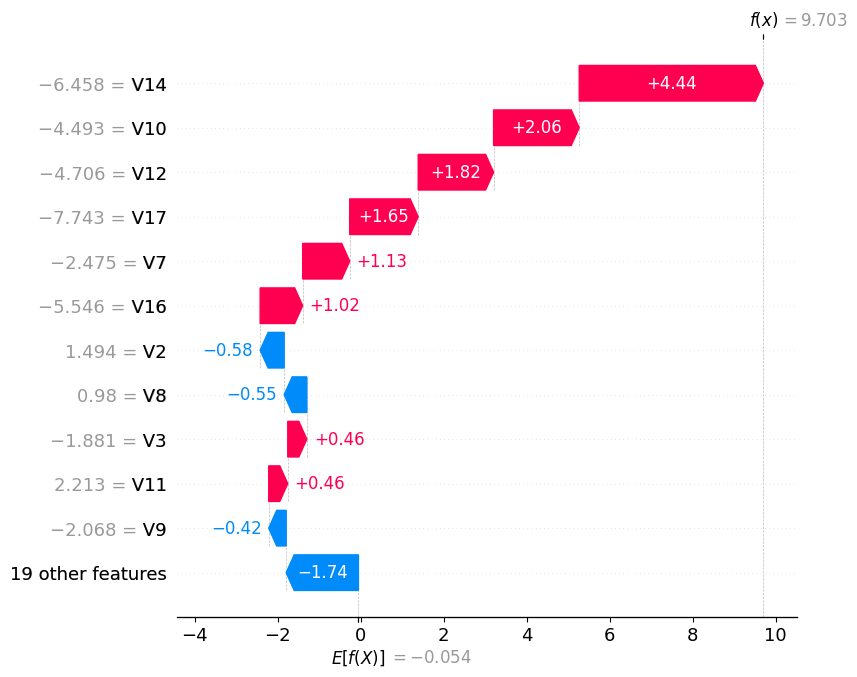

In [14]:
# Explicação de UMA fraude que o modelo detectou
pos = np.where((y_test.values == 1) & (probas["XGBoost"] >= 0.5))[0][0]
shap_uma = explainer(X_test_sc.iloc[[pos]])
print(f"Probabilidade de fraude atribuída: {probas['XGBoost'][pos]:.3f}")
shap.plots.waterfall(shap_uma[0], max_display=12)

**Como ler:**

**Beeswarm (visão geral):** cada ponto é uma transação. Vermelho é valor alto da variável, azul é valor baixo. Pontos à direita empurram para “fraude”, à esquerda para “normal”. Se os pontos azuis de uma variável como V14 ficarem à direita, valores baixos de V14 indicam fraude.

**Waterfall (uma transação):** começa no valor médio do modelo e mostra quanto cada variável somou ou subtraiu até chegar à decisão final. É a resposta para “por que esta transação foi marcada?”. Os valores estão em log-odds, a escala interna do XGBoost, mas a leitura de direção e tamanho vale do mesmo jeito.

**Diferencial — Peso de classe × undersampling × oversampling**

Esta é a seção “o que você mudou em relação à Expert”. O enunciado sugere testar as alternativas, e a regra é: reamostrar só o treino. O teste continua com a proporção real, senão as métricas viram ficção.

In [15]:
!pip install -q imbalanced-learn
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

X_under, y_under = RandomUnderSampler(random_state=42).fit_resample(X_train_sc, y_train)
X_smote, y_smote = SMOTE(random_state=42).fit_resample(X_train_sc, y_train)

print("Original:     ", y_train.value_counts().to_dict())
print("Undersampling:", y_under.value_counts().to_dict())
print("SMOTE:        ", y_smote.value_counts().to_dict())

estrategias = {
    "Peso de classe": (X_train_sc, y_train, LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
    "Undersampling":  (X_under, y_under, LogisticRegression(max_iter=1000, random_state=42)),
    "SMOTE":          (X_smote, y_smote, LogisticRegression(max_iter=1000, random_state=42)),
}

res_balanceamento = {}
for nome, (Xt, yt, modelo) in estrategias.items():
    modelo.fit(Xt, yt)
    res_balanceamento[nome] = avaliar(y_test, modelo.predict_proba(X_test_sc)[:, 1])

pd.DataFrame(res_balanceamento).T.round(3)

Original:      {0: 227451, 1: 394}
Undersampling: {0: 394, 1: 394}
SMOTE:         {0: 227451, 1: 227451}


,Recall,Precisão,F1,ROC AUC,PR AUC
Peso de classe,0.908,0.055,0.104,0.971,0.713
Undersampling,0.918,0.037,0.071,0.977,0.610
SMOTE,0.918,0.054,0.102,0.971,0.719


Undersampling joga fora a maioria das transações normais e treina com ~394 de cada. É rápido, mas descarta muita informação.
SMOTE cria fraudes sintéticas interpolando fraudes vizinhas até empatar com as normais.
Usei regressão logística aqui para isolar o efeito da técnica de balanceamento, já que o modelo é o mesmo nas três linhas, e porque roda rápido. Comparar o recall das três é o que o enunciado pede em “Ideias para Evoluir”.